
--- LDA Component Analysis ---
Explained Variance Ratio by Single Discriminant: 1.0000

--- Performance Comparison: Raw vs PCA vs LDA ---
             Approach  Accuracy  Precision   Recall  F1-Score  ROC-AUC
    Raw Features (14)  0.962685   0.888333 0.859677  0.873770 0.989791
    PCA Component (1)  0.953719   0.865417 0.819355  0.841756 0.985412
    LDA Component (1)  0.955658   0.851852 0.853226  0.852538 0.986575
Direct LDA Classifier  0.955173   0.845787 0.858065  0.851882 0.986575

Experiment 14 Completed Successfully


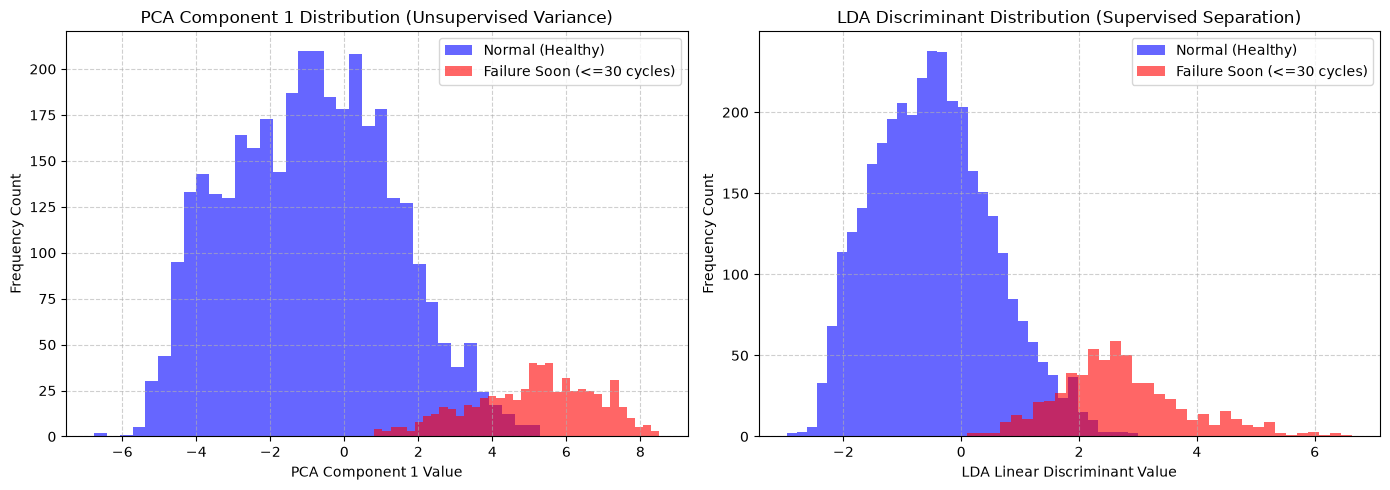

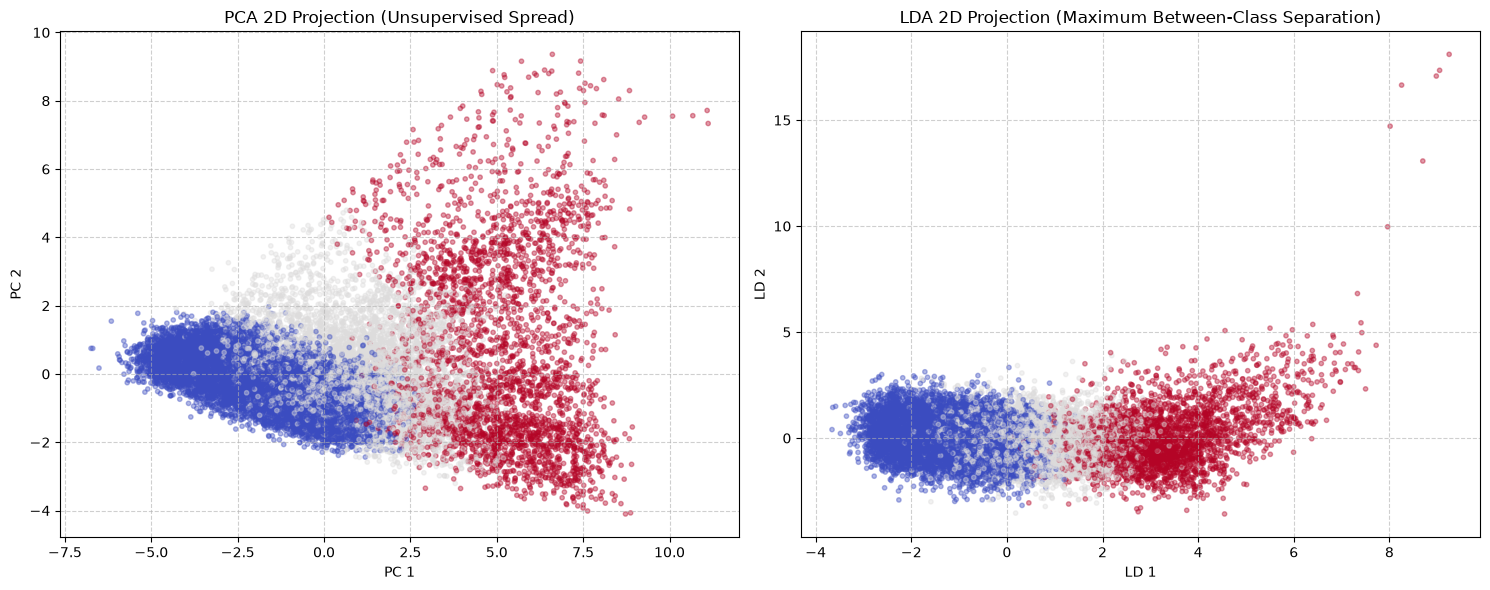

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score


# Load C-MAPSS telemetry dataset
cols = ["engine_id", "cycle", "setting_1", "setting_2", "setting_3"] + [f"sensor_{i}" for i in range(1, 22)]
df = pd.read_csv("../dataset/CMAPSSData/train_FD001.txt", sep=r"\s+", header=None, names=cols)

df["RUL"] = df.groupby("engine_id")["cycle"].transform("max") - df["cycle"]
df["failure_soon"] = (df["RUL"] <= 30).astype(int)

# Informative degradation sensors
sensor_features = ["sensor_2", "sensor_3", "sensor_4", "sensor_7", "sensor_8", 
                   "sensor_9", "sensor_11", "sensor_12", "sensor_13", "sensor_14", 
                   "sensor_15", "sensor_17", "sensor_20", "sensor_21"]

X = df[sensor_features]
y = df["failure_soon"]

# Stratified split to evaluate true out-of-sample transformation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 1. Implement LDA for Supervised Dimensionality Reduction
lda = LinearDiscriminantAnalysis(n_components=1)
X_train_lda = lda.fit_transform(X_train_scaled, y_train)
X_test_lda = lda.transform(X_test_scaled)

print("\n--- LDA Component Analysis ---")
print(f"Explained Variance Ratio by Single Discriminant: {lda.explained_variance_ratio_[0]:.4f}")

# 2. Implement Unsupervised PCA for Comparison (1st PC)
pca = PCA(n_components=1, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# 3. Visualize 1D Class Separation: PCA-1 vs LDA-1
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# PCA Component 1 Histogram (Unsupervised)
axes[0].hist(X_test_pca[y_test == 0, 0], bins=35, alpha=0.6, color='blue', label='Normal (Healthy)')
axes[0].hist(X_test_pca[y_test == 1, 0], bins=35, alpha=0.6, color='red', label='Failure Soon (<=30 cycles)')
axes[0].set_xlabel("PCA Component 1 Value")
axes[0].set_ylabel("Frequency Count")
axes[0].set_title("PCA Component 1 Distribution (Unsupervised Variance)")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.6)

# LDA Component 1 Histogram (Supervised Discriminant)
axes[1].hist(X_test_lda[y_test == 0, 0], bins=35, alpha=0.6, color='blue', label='Normal (Healthy)')
axes[1].hist(X_test_lda[y_test == 1, 0], bins=35, alpha=0.6, color='red', label='Failure Soon (<=30 cycles)')
axes[1].set_xlabel("LDA Linear Discriminant Value")
axes[1].set_ylabel("Frequency Count")
axes[1].set_title("LDA Discriminant Distribution (Supervised Separation)")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.show()

# 4. Multi-State 2D Visualization (3 Operational Health Classes)
# Class 0: Healthy (>90 cycles), Class 1: Moderate Wear (30-90 cycles), Class 2: Critical (<=30 cycles)
def assign_health_state(rul):
    if rul > 90: return 0
    elif rul > 30: return 1
    else: return 2

df["health_state"] = df["RUL"].apply(assign_health_state)
y_multi = df["health_state"]

X_scaled_all = scaler.fit_transform(X)

pca_2 = PCA(n_components=2, random_state=42)
X_pca_2 = pca_2.fit_transform(X_scaled_all)

lda_2 = LinearDiscriminantAnalysis(n_components=2)
X_lda_2 = lda_2.fit_transform(X_scaled_all, y_multi)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

scatter_pca = axes[0].scatter(X_pca_2[:, 0], X_pca_2[:, 1], c=y_multi, cmap="coolwarm", alpha=0.4, s=10)
axes[0].set_xlabel("PC 1")
axes[0].set_ylabel("PC 2")
axes[0].set_title("PCA 2D Projection (Unsupervised Spread)")
axes[0].grid(True, linestyle="--", alpha=0.6)

scatter_lda = axes[1].scatter(X_lda_2[:, 0], X_lda_2[:, 1], c=y_multi, cmap="coolwarm", alpha=0.4, s=10)
axes[1].set_xlabel("LD 1")
axes[1].set_ylabel("LD 2")
axes[1].set_title("LDA 2D Projection (Maximum Between-Class Separation)")
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.show()

# 5. Quantitative Model Comparison: Raw vs PCA-1 vs LDA-1 vs LDA Classifier
clf_raw = LogisticRegression(random_state=42)
clf_raw.fit(X_train_scaled, y_train)
pred_raw = clf_raw.predict(X_test_scaled)
auc_raw = roc_auc_score(y_test, clf_raw.predict_proba(X_test_scaled)[:, 1])

clf_pca = LogisticRegression(random_state=42)
clf_pca.fit(X_train_pca, y_train)
pred_pca = clf_pca.predict(X_test_pca)
auc_pca = roc_auc_score(y_test, clf_pca.predict_proba(X_test_pca)[:, 1])

clf_lda = LogisticRegression(random_state=42)
clf_lda.fit(X_train_lda, y_train)
pred_lda = clf_lda.predict(X_test_lda)
auc_lda = roc_auc_score(y_test, clf_lda.predict_proba(X_test_lda)[:, 1])

# Direct LDA classification model
pred_direct_lda = lda.predict(X_test_scaled)
auc_direct_lda = roc_auc_score(y_test, lda.predict_proba(X_test_scaled)[:, 1])

comparison_table = pd.DataFrame({
    "Approach": ["Raw Features (14)", "PCA Component (1)", "LDA Component (1)", "Direct LDA Classifier"],
    "Accuracy": [accuracy_score(y_test, pred_raw), accuracy_score(y_test, pred_pca), 
                 accuracy_score(y_test, pred_lda), accuracy_score(y_test, pred_direct_lda)],
    "Precision": [precision_score(y_test, pred_raw), precision_score(y_test, pred_pca), 
                  precision_score(y_test, pred_lda), precision_score(y_test, pred_direct_lda)],
    "Recall": [recall_score(y_test, pred_raw), recall_score(y_test, pred_pca), 
               recall_score(y_test, pred_lda), recall_score(y_test, pred_direct_lda)],
    "F1-Score": [f1_score(y_test, pred_raw), f1_score(y_test, pred_pca), 
                 f1_score(y_test, pred_lda), f1_score(y_test, pred_direct_lda)],
    "ROC-AUC": [auc_raw, auc_pca, auc_lda, auc_direct_lda]
})

print("\n--- Performance Comparison: Raw vs PCA vs LDA ---")
print(comparison_table.to_string(index=False))

print("Experiment 14 Completed Successfully")